# NN_L1_activations

**Activation functions of neural networks (sigmoid, tanh, ReLU, GELU) and their derivatives; analytic curves, a mechanism illustration without data.**

Neural Networks and Deep Learning (NN), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L1/NN_L1_activations/NN_L1_activations.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 1 of *Neural Networks and Deep Learning*: the chart `activations` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

largest derivative of the sigmoid = 0.25   [act.sigmoid_max_grad]


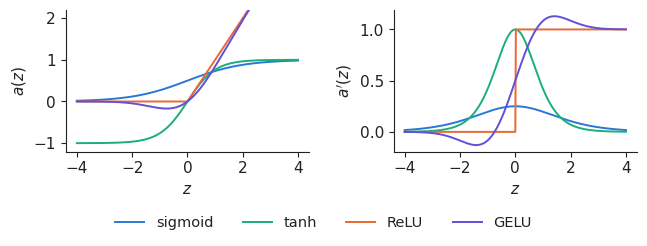

In [3]:
from math import erf
z = np.linspace(-4, 4, 401); sig = 1 / (1 + np.exp(-z))
gelu = 0.5 * z * (1 + np.vectorize(lambda u: erf(u / np.sqrt(2)))(z))
acts = {'sigmoid': (sig, sig * (1 - sig)), 'tanh': (np.tanh(z), 1 - np.tanh(z) ** 2), 'ReLU': (np.maximum(z, 0), (z > 0).astype(float)),
        'GELU': (gelu, np.gradient(gelu, z))}
show('act.sigmoid_max_grad', 'largest derivative of the sigmoid', round(float((sig * (1 - sig)).max()), 2))
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.5))
for (nm, (f, d)), c in zip(acts.items(), [PAL['data'], PAL['benchmark'], PAL['model'], '#6250d6']):
    axs[0].plot(z, f, color=c, label=nm); axs[1].plot(z, d, color=c)
axs[0].set_ylim(-1.2, 2.2); axs[0].set_ylabel('$a(z)$'); axs[1].set_ylabel("$a'(z)$")
for ax in axs:
    ax.set_xlabel('$z$')
legend_bottom(fig); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('activations.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()